<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Auto_Ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# STEP 1 : DOWNLOAD & FEATURE ENGINEERING
# ==========================================

!pip install yfinance ta flaml -q

import yfinance as yf
import pandas as pd
import numpy as np

from ta.momentum import RSIIndicator
from ta.trend import MACD
from ta.volatility import AverageTrueRange

# Download NIFTY
df = yf.download(
    "^NSEI",
    start="2015-01-01",
    end="2025-12-31",
    auto_adjust=True
)

# Flatten columns
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Returns
df["Return"] = df["Close"].pct_change()

# RSI
df["RSI"] = RSIIndicator(df["Close"]).rsi()

# MACD
df["MACD"] = MACD(df["Close"]).macd()

# ATR
df["ATR"] = AverageTrueRange(
    df["High"],
    df["Low"],
    df["Close"]
).average_true_range()

# Moving Average
df["MA20"] = df["Close"].rolling(20).mean()

# Volatility
df["Volatility"] = df["Return"].rolling(20).std()

# Momentum
df["Momentum"] = df["Close"] - df["Close"].shift(10)

df.dropna(inplace=True)

print(df.head())

print("\nDataset Shape:", df.shape)

[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open  Volume  \
Date                                                                     
2015-02-09  8526.349609  8605.549805  8516.349609  8584.400391  146800   
2015-02-10  8565.549805  8646.250000  8470.500000  8478.099609  196200   
2015-02-11  8627.400391  8651.950195  8593.650391  8603.299805  161600   
2015-02-12  8711.549805  8732.549805  8599.250000  8676.950195  158800   
2015-02-13  8805.500000  8822.099609  8729.650391  8741.500000  221900   

Price         Return        RSI       MACD         ATR         MA20  \
Date                                                                  
2015-02-09 -0.015552  43.279644  70.149962  117.333817  8662.175000   
2015-02-10  0.004598  46.376984  54.827243  121.506401  8674.302490   
2015-02-11  0.007221  50.930067  47.131401  118.998829  8690.702490   
2015-02-12  0.009754  56.359295  47.277558  120.020327  8712.402490   
2015-02-13  0.010785  61.483232  54.347897  119.343861 

In [ ]:
# ==========================================
# STEP 2 : CREATE FUTURE LABELS
# ==========================================

# Number of future days to inspect
future_days = 5

# Threshold (2%)
threshold = 0.02

# Future highest high
df["FutureHigh"] = (
    df["High"]
    .shift(-1)
    .rolling(future_days)
    .max()
)

# Future lowest low
df["FutureLow"] = (
    df["Low"]
    .shift(-1)
    .rolling(future_days)
    .min()
)

# Percentage move
df["FutureUp"] = (
    df["FutureHigh"] - df["Close"]
) / df["Close"]

df["FutureDown"] = (
    df["Close"] - df["FutureLow"]
) / df["Close"]

# Default label
# 0 = Normal
df["Target"] = 0

# Resistance
df.loc[df["FutureUp"] >= threshold, "Target"] = 2

# Support
df.loc[df["FutureDown"] >= threshold, "Target"] = 1

# Remove last rows where future is unknown
df.dropna(inplace=True)

print("=" * 50)
print("Target Distribution")
print(df["Target"].value_counts())

print("=" * 50)
print(df[[
    "Close",
    "FutureHigh",
    "FutureLow",
    "FutureUp",
    "FutureDown",
    "Target"
]].head(10))

Target Distribution
Target
0    1521
1     712
2     444
Name: count, dtype: int64
Price             Close   FutureHigh    FutureLow  FutureUp  FutureDown  \
Date                                                                      
2015-02-13  8805.500000  8870.099609  8470.500000  0.007336    0.038044   
2015-02-16  8809.349609  8894.299805  8593.650391  0.009643    0.024485   
2015-02-18  8869.099609  8913.450195  8599.250000  0.005001    0.030426   
2015-02-19  8895.299805  8913.450195  8729.650391  0.002040    0.018622   
2015-02-20  8833.599609  8913.450195  8736.099609  0.009039    0.011037   
2015-02-23  8754.950195  8913.450195  8726.750000  0.018104    0.003221   
2015-02-24  8762.099609  8913.450195  8726.750000  0.017273    0.004034   
2015-02-25  8767.250000  8899.950195  8669.450195  0.015136    0.011155   
2015-02-26  8683.849609  8869.000000  8669.450195  0.021321    0.001658   
2015-02-27  8844.599609  8972.349609  8669.450195  0.014444    0.019803   

Price       Targ

In [ ]:
print(df["Target"].value_counts())

Target
0    1521
1     712
2     444
Name: count, dtype: int64


In [ ]:
# ==========================================
# STEP 3 : TRAIN FLAML CLASSIFIER
# ==========================================

from flaml import AutoML
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# --------------------------
# Features
# --------------------------

features = [
    "RSI",
    "MACD",
    "ATR",
    "MA20",
    "Volatility",
    "Momentum",
    "Volume"
]

X = df[features]

y = df["Target"]

# --------------------------
# Time Series Split
# --------------------------

split = int(len(df) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# --------------------------
# Train AutoML
# --------------------------

automl = AutoML()

automl.fit(
    X_train=X_train,
    y_train=y_train,
    task="classification",
    metric="accuracy",
    time_budget=60
)

# --------------------------
# Prediction
# --------------------------

pred = automl.predict(X_test)

# --------------------------
# Evaluation
# --------------------------

print("="*50)
print("Accuracy")
print(accuracy_score(y_test, pred))

print("="*50)
print("Confusion Matrix")
print(confusion_matrix(y_test, pred))

print("="*50)
print("Classification Report")
print(classification_report(y_test, pred))

print("="*50)
print("Best Model")
print(automl.model)

print("="*50)
print("Best Parameters")
print(automl.best_config)

[flaml.automl.logger: 07-04 03:13:56] {2375} INFO - task = classification
[flaml.automl.logger: 07-04 03:13:56] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 07-04 03:13:56] {2489} INFO - Minimizing error metric: 1-accuracy
[flaml.automl.logger: 07-04 03:13:56] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 07-04 03:13:56] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 07-04 03:13:56] {3046} INFO - Estimated sufficient time budget=1356s. Estimated necessary time budget=31s.
[flaml.automl.logger: 07-04 03:13:56] {3097} INFO -  at 0.2s,	estimator lgbm's best error=4.4698e-01,	best estimator lgbm's best error=4.4698e-01
[flaml.automl.logger: 07-04 03:13:56] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 07-04 03:13:56] {3097} INFO -  at 0.3s,	estimator lgbm's best error=4.4698e-01,	best estimator lgbm's best error=4.4698e-01
[flaml.auto

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 07-04 03:13:57] {3097} INFO -  at 0.4s,	estimator sgd's best error=4.6193e-01,	best estimator lgbm's best error=3.3347e-01
[flaml.automl.logger: 07-04 03:13:57] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 07-04 03:13:57] {3097} INFO -  at 0.5s,	estimator lgbm's best error=2.9425e-01,	best estimator lgbm's best error=2.9425e-01
[flaml.automl.logger: 07-04 03:13:57] {2911} INFO - iteration 5, current learner lgbm
[flaml.automl.logger: 07-04 03:13:57] {3097} INFO -  at 0.6s,	estimator lgbm's best error=2.9425e-01,	best estimator lgbm's best error=2.9425e-01
[flaml.automl.logger: 07-04 03:13:57] {2911} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 07-04 03:13:57] {3097} INFO -  at 0.7s,	estimator lgbm's best error=2.7790e-01,	best estimator lgbm's best error=2.7790e-01
[flaml.automl.logger: 07-04 03:13:57] {2911} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 07-04 03:13:57] {3097} INFO -  at 0.9s,	estimator l

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 07-04 03:14:57] {3097} INFO -  at 60.4s,	estimator lrl1's best error=4.3811e-01,	best estimator lgbm's best error=2.4987e-01
[flaml.automl.logger: 07-04 03:14:58] {3359} INFO - retrain lgbm for 1.9s
[flaml.automl.logger: 07-04 03:14:58] {3362} INFO - retrained model: LGBMClassifier(colsample_bytree=np.float64(0.9440691071067414),
               learning_rate=np.float64(0.23563209219525533), max_bin=255,
               min_child_samples=9, n_estimators=218, n_jobs=-1, num_leaves=48,
               reg_alpha=np.float64(0.001551515657942566),
               reg_lambda=np.float64(1.465573664760151), verbose=-1)
[flaml.automl.logger: 07-04 03:14:58] {2636} INFO - fit succeeded
[flaml.automl.logger: 07-04 03:14:58] {2637} INFO - Time taken to find the best model: 51.10143542289734
Accuracy
0.7164179104477612
Confusion Matrix
[[282  27  60]
 [ 45  47  10]
 [  9   1  55]]
Classification Report
              precision    recall  f1-score   support

           0       0.84 

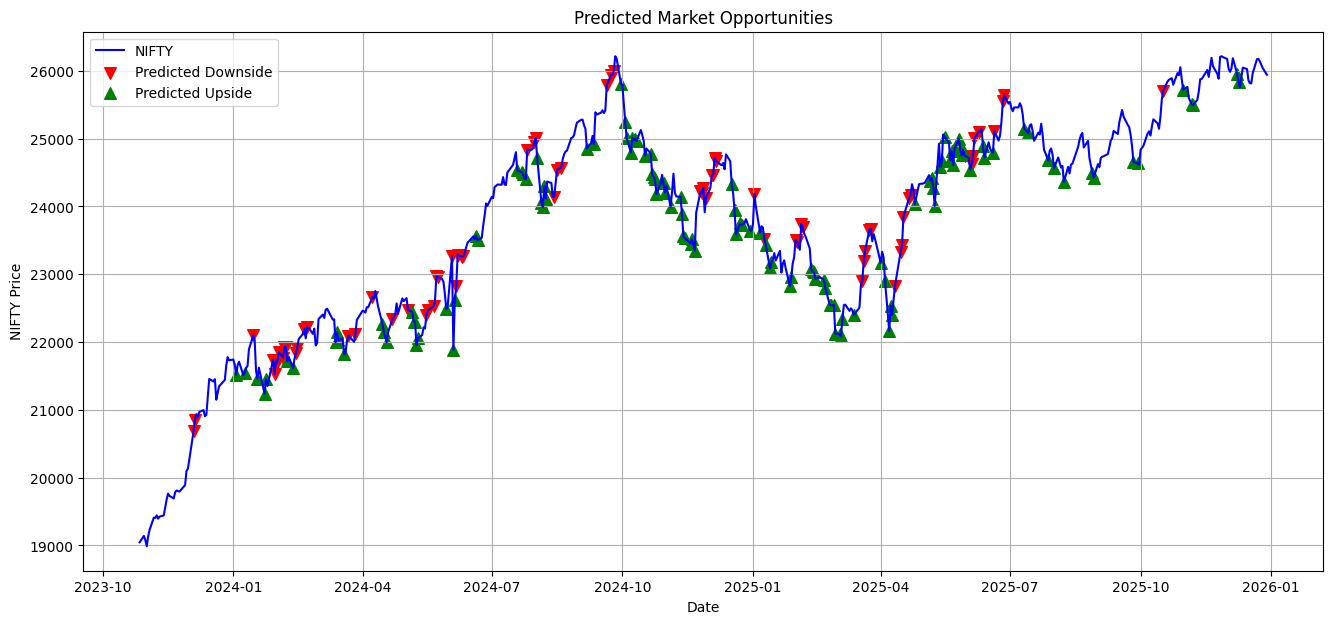

In [ ]:
# ==========================================
# STEP 4 : VISUALIZE PREDICTIONS
# ==========================================

import matplotlib.pyplot as plt

test_df = df.iloc[split:].copy()
test_df["Prediction"] = pred

plt.figure(figsize=(16,7))

plt.plot(test_df.index,
         test_df["Close"],
         color="blue",
         label="NIFTY")

# Predicted Downside
plt.scatter(
    test_df.index[test_df["Prediction"]==1],
    test_df["Close"][test_df["Prediction"]==1],
    color="red",
    marker="v",
    s=70,
    label="Predicted Downside"
)

# Predicted Upside
plt.scatter(
    test_df.index[test_df["Prediction"]==2],
    test_df["Close"][test_df["Prediction"]==2],
    color="green",
    marker="^",
    s=70,
    label="Predicted Upside"
)

plt.title("Predicted Market Opportunities")
plt.xlabel("Date")
plt.ylabel("NIFTY Price")
plt.legend()
plt.grid(True)

plt.show()